In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    classification_report,
    f1_score,
)
from sklearn.model_selection import (
    RandomizedSearchCV,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

In [ ]:
df_raw = pd.read_csv("data/water-quality.csv")
df_raw.to_csv("data/self_raw/raw_data.csv", index=False)
df_raw.info()

In [ ]:
df_raw.head()

Wasserqualität zeigt keinerlei fehlende Werte, Daten sind komplett 👍

Datentyp von Spalte "is_safe" wird jedoch von int auf bool umgestellt:

In [ ]:
#Umwandeln  von is_safe von int auf bool
df = df_raw.copy()
df["is_safe"] = df["is_safe"].astype(bool)
df.info()

In [ ]:
#Speichern von der 'bereinigten' Datei in 'data/self_cleaned/'
df.to_csv("data/self_cleaned/cleaned_data.csv", index=False)

**Target Column:**
Target-Column = 'is_safe'

**Problem:**
→ Klassifizierungsproblem (sicher vs. unsicher)

---
Beispiel Regression: Vorhersage eines Hauspreises, wie im King-County-Projekt
- Eingaben: Wohnfläche, Anzahl der Zimmer, Baujahr und Lage.
- Zielwert: Verkaufspreis.
- Vorhersage: beispielsweise 425.000 €.

→ Regression, weil das Modell einen Zahlenwert vorhersagt.

> Jetzt werden aus den Daten zwei DataFrames erstellt:
> - Eine Liste ohne Ergebnisse
> - Eine Liste mit nur den entsprechenden Ergebnissen

Das ist notwendig um das Modell zu trainieren.

In [ ]:
X = df.drop(columns="is_safe")
y = df["is_safe"]

In [ ]:
y.value_counts(dropna=False)

Man sieht mit y.value_counts die  Klassenverteilung von 'is_safe':
- ca. 89 % sind FALSE
- ca. 11 % sind TRUE

Dieses Verhältnis soll in Trainings- und Testdaten ähnlich bleiben, damit:
- Das Modell beim Lernen beide Klassen im ursprünglichen Verhältnis sieht
- Der Test den vorhandenen Datensatz möglichst gut widerspiegelt. Enthielte er zufällig fast nur unsichere Proben, könnten wir kaum beurteilen, wie gut das Modell sichere Proben erkennt

Ein extremes Beispiel: Im Test wären ausschließlich unsichere Proben.  \
Ein Modell, das immer „unsicher“ vorhersagt, hätte dann 100 % Accuracy, obwohl es keine sichere Probe erkennt.  \
```stratify=y``` verhindert solche zufälligen Verschiebungen bei der Aufteilung weitgehend.  \
Das bestehende Klassenungleichgewicht behebt es allerdings nicht.

Aufteilen der Daten in Trainings- und Testdaten:

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

Prüfen, ob die Klassenverteilung von 'is_safe' aus den  Grunddaten erhalten geblieben ist ('stratify = y' hilft hierbei):

In [ ]:
y_train.value_counts(normalize=True)

In [ ]:
y_test.value_counts(normalize=True)

Klassenverteilung ist erhalten geblieben 👍

Jetzt folgt die Pipeline aus Skalierung und Modell - sie verbindet zwei Schritte.

1. StandardScaler bringt die Messwerte auf vergleichbare Größenordnungen. Dafür lernt er beim Training den Mittelwert und die Standardabweichung jeder Eingabespalte. 

> - Die Daten haben unterschiedliche Werte von 0,0001 bis 100.000 usw. Eine größere Zahl bedeutet jedoch nicht automatisch, dass dieses Merkmal wichtiger ist.
> - Ohne Skalierung kann das Modell trotzdem funktionieren, aber Training und Ergebnis können ungünstiger ausfallen. Bei anderen Modellen, etwa Entscheidungsbäumen, ist diese Skalierung normalerweise nicht nötig.

2. LogisticRegression lernt anschließend aus den skalierten Messwerten, zwischen False und True zu unterscheiden.
Die Pipeline sorgt dafür, dass später auch Testdaten mit denselben beim Training gelernten Werten skaliert werden.

> - Das ist das eigentliche Modell, das den Zusammenhang zwischen Messwerten und is_safe lernt. Der Scaler allein kann keine Wasserprobe klassifizieren.
Für diese Aufgabe benötigt man ein Klassifikationsmodell.  \
Logistic Regression ist dafür ein einfacher Ausgangspunkt; andere Klassifikationsmodelle wären ebenfalls möglich.

In [ ]:
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression()),
])

**.fit()** bedeutet aus Daten lernen → die Pipeline trainieren 💪

1. Der StandardScaler lernt Mittelwert und Standardabweichung jeder Spalte aus X_train. Damit skaliert er die Trainingsdaten.

2. Die LogisticRegression lernt aus diesen skalierten Messwerten und den bekannten Antworten in y_train, welche Zusammenhänge auf sichere oder unsichere Wasserproben hinweisen. Dabei passt sie ihre Modellkoeffizienten an.

Die gelernten Werte werden in deiner Pipeline gespeichert.

---
- .fit() = Lernen mit Beispielen und bekannten Antworten
- .predict() = Das Gelernte auf weitere Beispiele anwenden

In [ ]:
pipeline.fit(X_train, y_train)

In [ ]:
X_train.head()

In [ ]:
y_train.head()

Nach .fit() steckt das Gelernte im Objekt pipeline – zunächst nur im Arbeitsspeicher deines laufenden Notebook-Kernels.
Es wird dabei nicht automatisch eine Datei gespeichert.

Die Pipeline enthält jetzt:
| Bestandteil | Was wurde beim Training gespeichert? |
|---|---|
| `StandardScaler` | Mittelwert und Standardabweichung jeder Eingabespalte |
| `LogisticRegression` | Gelernte Gewichte (**Koeffizienten**) und ein Basiswert (**Intercept**), aus denen das Modell seine Vorhersagen berechnet |


Die erkannten „Muster“ stecken also in gelernten Zahlenwerten, Beispielsweise im Modellkoeffizienten:
```pipeline.named_steps["model"].coef_```


Bei anschließenden  aufruf von ```pipeline.predict(X_test)``` greift die Pipeline auf diese gespeicherten Werte zurück.  \
→ Sie muss dafür nicht erneut lernen.


> **Wichtig für später:** Ein Neustart des Kernels löscht diesen Zustand aus dem Arbeitsspeicher.  \
Das Speichern der .ipynb-Datei bewahrt zwar Code und angezeigte Ausgaben, aber nicht automatisch das trainierte Modellobjekt.  \
Um es später ohne erneutes Training zu verwenden, speichern wir die gesamte trainierte Pipeline als Modelldatei.  \
Dadurch bleiben sowohl die Skalierungswerte als auch das gelernte Modell erhalten.

In [ ]:
pipeline.named_steps["model"].coef_

**.predict()** erstellt Vorhersagen für einen Datensatz, hier 'X_test'

Die Antworten dazu stehen in  'y_test' und dienen zur Bewertung des Models.

In [ ]:
y_pred = pipeline.predict(X_test)

Nun kommt die Bewertung über classification_report:

- y_test: tatsächliche Klassen
- y_pred: vorhergesagte Klassen

Der Bericht zeigt für False und True jeweils Precision, Recall und F1-Score.

Support gibt an, wie viele Testproben tatsächlich zur jeweiligen Klasse gehören.

In [ ]:
print(classification_report(y_test, y_pred))

| Kennzahl | Wert | Bedeutung |
|---|---:|---|
| **support** | 182 | Im Test sind tatsächlich 182 sichere Proben. |
| **Recall** | 0,33 | Von diesen sicheren Proben erkennt das Modell nur etwa **33 %** – ungefähr 60 Stück. |
| **Precision** | 0,71 | Von den Proben, die das Modell als sicher einstuft, sind etwa **71 % tatsächlich sicher**. |
| **F1-Score** | 0,45 | Fasst Precision und Recall zu einer gemeinsamen Kennzahl zusammen. |

Als Nächstes machen wir die Fehler als konkrete Anzahlen sichtbar.

In [ ]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["unsicher","sicher"]
)

plt.show()

Links steht die tatsächliche Klasse, unten die Vorhersage des Modells.
| Tatsächlich ↓ / Vorhergesagt → | Unsicher | Sicher |
|---|---:|---:|
| **Unsicher** | **1.394 richtig** als unsicher erkannt | **24 falsch** als sicher eingestuft |
| **Sicher** | **122 falsch** als unsicher eingestuft | **60 richtig** als sicher erkannt |

Die Diagonale von links oben nach rechts unten enthält die richtigen Vorhersagen

Die anderen beiden Felder enthalten die Fehler.

- Precision: Das Modell sagt bei 24 + 60 = 84 Proben „sicher“. Davon stimmen 60
- Recall: Tatsächlich sicher sind 122 + 60 = 182 Proben. Davon stimmen 60

Damit erkennt man genau, wie viele Proben richtig oder falsch zugeordnet wurden.

Das Grundmodell steht nun.

Jetzt folgt das Hyperparameter-Tuning → Wir prüfen, ob andere Modelleinstellungen bessere Ergebnisse liefern.

Zunächst halten wir den bisherigen F1-Score als Vergleichswert fest.

In [ ]:
baseline_f1 = f1_score(y_test, y_pred)
print(f"Baseline F1: {baseline_f1:.3f}")

Als erste Einstellung untersuchen wir **C** bei Logistic Regression.

Dieser Hyperparameter steuert die Stärke der Regularisierung, also wie stark große Modellkoeffizienten begrenzt werden:
- kleines **C**: stärkere Begrenzung
- großes **C**: schwächere Begrenzung

Dazu erstellen wir ein  Dictionary:

In [ ]:
param_distributions_C = {
    "model__C":[0.01, 0.1, 1, 10, 100]
}

```model__C``` bedeutet: Parameter **C** des Pipeline-Schritts "model".  \
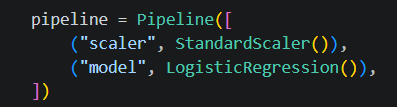  \
Die beiden Unterstriche verbinden Schrittname und Parametername.

Um den besten Wert zu finden benutzen wir akribische Suche mittels ```RanomizedSearchCV``` mit folgenden Parametern:
- **estimator** = pipeline: Untersucht wird die gesamte Pipeline inklusive Skalierung
- **param_distributions**: Hier stehen die möglichen Werte für ```model__C``` aus ```param_distributions_C```
- **n_iter=5**: Fünf Einstellungen ausprobieren – bei deiner Liste werden damit alle fünf Werte getestet
- **scoring="f1"**: Scoring wird durch ```F1``` bestimmt. ```F1_aktuell``` >  ```F1_zuvor```? → Modell würde sich mit diesem Parameter **C** verbessern 👍
- **cv=5**: Trainingsdaten in fünf Teile aufteilen. Für jede Einstellung wird fünfmal trainiert; jeweils auf vier Teilen, während der übrige Teil zur Bewertung dient
- **random_state=42**: Die Proben werden standardmäßig zufällig aufgeteilt. Mit einem festen Startwert erhältst man bei denselben Daten und Einstellungen jedes Mal dieselbe Aufteilung. Die Zahl 42 ist beliebig; beispielsweise würde 7 ebenfalls funktionieren, aber eine andere Aufteilung erzeugen. Das hilft, Modelle fair miteinander zu vergleichen.

In [ ]:
hyper_param_C_search = RandomizedSearchCV(
    estimator=pipeline,
    param_distributions=param_distributions_C,
    n_iter=5,
    scoring="f1",
    cv=5,
    random_state=42
)

Jetzt wird das Modell mit allen angegebenen Varianten von **C** mit den Trainingsdaten ```X_train/y_train``` durchtrainiert und der beste **F1-Score** wird in ```hyper_param_C_search``` behalten.

In [ ]:
hyper_param_C_search.fit(X_train, y_train)

Wie zuvor das Basismodell, muss nun das neu trainierte Modell ```hyper_param_C_search``` vorhersagen treffen an der selben Datengrundlage ```X_test```.

In [ ]:
y_pred_tuned_C = hyper_param_C_search.predict(X_test)

Zum Bewerten werden die **F1-Scores** verglichen:

In [ ]:
print("Baseline:", classification_report(y_test, y_pred, digits=5))

print("After Tuning:", classification_report(y_test, y_pred_tuned_C, digits=5))

print("Best Parameter for C:", hyper_param_C_search.best_params_)

**F1-Score** vorher ist exakt gleich zu nach dem Tuning.
Daher sicherheitshalber prüfen, ob durch unterschiedliche Parameter **C** sich überhaupt etwas am **F1-Score** ändert:

In [ ]:
results = pd.DataFrame(hyper_param_C_search.cv_results_)

In ```results``` stehen deutlich mehr Infos als wir herauslesen wollen.
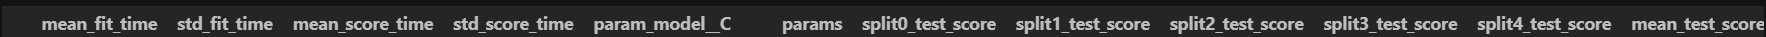

Daher wird der Frame angepasst, um einfach vergleichen zu können.

In [ ]:
comparison = results[
    ["param_model__C", "mean_test_score", "std_test_score", "rank_test_score"]
].rename(columns={
    "param_model__C": "C",
    "mean_test_score": "F1_Mittelwert",
    "std_test_score": "F1_Streuung",
    "rank_test_score": "Rang",
})

comparison.sort_values("C").round(6)

In der Tabelle sieht man die Mittelwert für **F1**.  \
Es ist zu erkenne, dass sich **F1** ändert, aber mit **C** = 10 oder 100 sich der Bestwert für **C** ergibt.  \
Somit war **C** des Basismodells (**C=1** als Standardwert) bereits gut gewählt.
In der Cross-Validation schneiden C=10 und C=100 etwas besser ab als C=1.  \
Auf den separaten Testdaten bringt das ausgewählte Modell keine Verbesserung des **F1-Scores.**

**C** ist nur eine Stellschraube.  \
Damit wurde nur die Regularisierung verändert.
Das Modell kann trotzdem zu einfach sein, um die Zusammenhänge gut abzubilden.

Mögliche nächste Schritte um Modell zu verbessern:
| Ansatz | Was verändert sich? |
|---|---|
| **Klassengewichtung** | Die seltenere Klasse erhält beim Training mehr Gewicht. |
| **Entscheidungsschwelle** | Wir verändern, ab welcher vorhergesagten Wahrscheinlichkeit eine Probe als sicher gilt. |
| **Anderes Modell** | Beispielsweise können Entscheidungsbäume oder Random Forests andere Zusammenhänge lernen. |
| **Bessere Merkmale und Daten** | Wir untersuchen fehlerhafte Werte, fehlende Informationen oder hilfreiche Kombinationen der Messwerte. |

Als erstes verändern wir die Klassengewichtung, heißt Proben mit ```is_safe``` haben mehr Bedeutung als unsichere Proben.  \
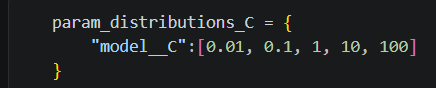  \
→ Standardmäßig ist ```C=1``` und ```class_weight=None```

Dazu wird ein neues Dictionary aufgesetzt mit beiden Hyperparametern geändert:

In [ ]:
param_distributions_C_class_weight = {
    "model__C": [0.01, 0.1, 1, 10, 100],
    "model__class_weight": [None, "balanced"],
}

```n_iter``` muss nun 10 sein, da 5x2 Werte betrachtet werden müssen.

In [ ]:
hyper_param_C_class_weight_search = RandomizedSearchCV(
    estimator=pipeline,
    param_distributions=param_distributions_C_class_weight,
    n_iter=10,
    scoring="f1",
    cv=5,
    random_state=42
)

In [ ]:
hyper_param_C_class_weight_search.fit(X_train, y_train)

In [ ]:
y_pred_tuned_C_class_weight = hyper_param_C_class_weight_search.predict(X_test)

In [ ]:
print("Baseline:")
print(classification_report(y_test, y_pred, digits=5))

print("After Tuning C and class_weight:")
print(classification_report(y_test, y_pred_tuned_C_class_weight, digits=5))

print("Best Parameter for C and class_weight:", hyper_param_C_class_weight_search.best_params_)

Man sieht das ``Recall`` steigt, also mehr Proben die sicher sind als sicher vorhergesagt werden, dabei werden allerdings auch mehr unsichere Proben als sicher bewertet.  \
→ ````Precision```` fällt deutlich. Dadurch ist der **F1-Score** auch schlechter.

In [ ]:
#Basismodell
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["unsicher","sicher"]
)

plt.show()

In [ ]:
#Getuntes Modell
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_tuned_C_class_weight,
    display_labels=["unsicher","sicher"]
)

plt.show()

Die Entscheidungsschwelle ändern ist ein sinnvoller nächster Versuch.  \
Sie verändert, ab wann das Modell „sicher“ vorhersagt – die gelernten Zusammenhänge bleiben dabei gleich.  \
Die Schwelle liegt standardmäßig bei 0.5

| Änderung | Typische Auswirkung |
|---|---|
| **Schwelle erhöhen**, beispielsweise auf 0,7 | Weniger Proben werden als sicher eingestuft. Recall sinkt; Precision kann steigen. |
| **Schwelle senken**, beispielsweise auf 0,3 | Mehr Proben werden als sicher eingestuft. Recall steigt; Precision kann sinken. |

→ Beides nicht hilfreich, ein guten Modell zu erstellen

Nächster sinnvoller Schritt: Aktuelles Modell mit einem **Random Forest** vergleichen.

Ein **Random Forest** kombiniert viele Entscheidungsbäume.  \
Diese können unterschiedliche Wertebereiche und Kombinationen von Merkmalen berücksichtigen.

Auch **Gradient Boosting** wäre anschließend ein sinnvoller Kandidat.  \
Ob sie bei den Daten besser funktionieren, muss geprüft werden.

>Überlegung: Wann ist eine Probe unsicher? Ein Mensch würde z.B. prüfen, ob Proben gewisse Grenzwerte an Inhaltsstoffen überschreiten. Wenn dies der Fall ist, ist die Probe unsicher.

→ Wenn zuverlässige Grenzwerte und vollständige Entscheidungsregeln bereits bekannt sind, braucht es dafür nicht unbedingt Machine Learning, man kann die Regeln direkt programmieren.  \
Das wäre nachvollziehbar und würde exakt die vorgegebenen Bedingungen prüfen.

Ein Entscheidungsbaum versucht dagegen herauszufinden:  \
„Mit welchem Inhaltsstoff und welchem Trennwert kann ich sichere und unsichere Trainingsproben möglichst gut unterscheiden?“  \
Seine gelernten Trennwerte sind deshalb nicht automatisch fachlich gültige Grenzwerte.

Ein Gradient-Boosting-Modell arbeitet tatsächlich mit vielen Entscheidungsbäumen.  \
Es kombiniert deren Beiträge zu einer Vorhersage.  \
→ Dadurch ist es leistungsfähiger, aber schwerer nachzuvollziehen als ein einzelner Baum.

## Neues Modell: Histogram Gradient Boosting

Als Ergänzung verwenden wir jetzt `HistGradientBoostingClassifier`.  \
Das Modell kombiniert viele Entscheidungsbäume, die schrittweise die Fehler des bisherigen Gesamtmodells verringern sollen.  \
So kann es auch Merkmalskombinationen und unterschiedliche Wertebereiche abbilden.

Die Baseline bleibt in `pipeline` erhalten. Für das neue Modell verwenden wir eigene Variablen mit `hgb` im Namen.

In [ ]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix

# Ergänzende Imports, damit der neue Abschnitt verständlich zusammenhängend ist.
import matplotlib.pyplot as plt

### 1. Modell mit den ausgewählten Hyperparametern anlegen

| Parameter | Wert | Bedeutung |
| --- | --- | --- |
| `learning_rate` | `0.1` | Stärke des Beitrags jedes neuen Boosting-Schritts |
| `max_iter` | `200` | Anzahl der Boosting-Schritte |
| `max_leaf_nodes` | `31` | Höchstens 31 Blätter pro Baum |
| `min_samples_leaf` | `5` | Mindestens fünf Trainingsproben pro Blatt |
| `l2_regularization` | `0.0` | Keine zusätzliche L2-Regularisierung der Blattwerte |
| `class_weight` | `"balanced"` | Seltenere Klassen beim Training stärker gewichten |
| `early_stopping` | `False` | Alle angegebenen Boosting-Schritte durchführen |
| `random_state` | `42` | Zufällige Schritte reproduzierbar halten |

Dass `balanced` bei Logistic Regression den Test-F1 nicht verbessert hat, bedeutet nicht, dass es bei einem anderen Modell ebenfalls ungeeignet ist. Wir bewerten die Kombination aus Modelltyp und Hyperparametern.

In [ ]:
hgb_params = {
    "learning_rate": 0.1,
    "max_iter": 200,
    "max_leaf_nodes": 31,
    "min_samples_leaf": 5,
    "l2_regularization": 0.0,
    "class_weight": "balanced",
    "early_stopping": False,
    "random_state": 42,
}

model_hgb = HistGradientBoostingClassifier(**hgb_params)
print(model_hgb)

### 2. Cross-Validation auf den Trainingsdaten

Wir prüfen die festgelegte Konfiguration mit denselben fünf stratifizierten Folds wie bisher.  \
`cross_validate` trainiert dafür Kopien des Modells.  \
`model_hgb` wird dadurch noch nicht auf allen Trainingsdaten trainiert.

`test_f1` bezeichnet hier die Bewertung auf dem jeweils zurückgehaltenen **CV-Fold innerhalb der Trainingsdaten**.  \
Die separaten Testdaten `X_test` und `y_test` werden nicht verwendet.  \
Die ausgewählte Konfiguration wurde bereits anhand dieser Folds gesucht; diese erneute Berechnung ist eine Reproduktion, keine unabhängige Validierung.

In [ ]:
hgb_cv = StratifiedKFold(n_splits=5, shuffle=False)
hgb_cv_results = cross_validate(
    model_hgb,
    X_train,
    y_train,
    cv=hgb_cv,
    scoring={"f1": "f1", "precision": "precision", "recall": "recall"},
    n_jobs=1,
    error_score="raise",
)

hgb_cv_summary = pd.DataFrame({
    "Metrik": ["F1 (sicher)", "Precision (sicher)", "Recall (sicher)"],
    "CV-Mittelwert": [hgb_cv_results[f"test_{metric}"].mean()
                      for metric in ["f1", "precision", "recall"]],
    "CV-Standardabweichung": [hgb_cv_results[f"test_{metric}"].std()
                              for metric in ["f1", "precision", "recall"]],
})
print(hgb_cv_summary.to_string(index=False, float_format=lambda value: f"{value:.5f}"))

### 3. Modell trainieren und Vorhersagen erstellen

Jetzt wird das ausgewählte Modell auf allen Trainingsproben trainiert.  \
Anschließend bekommt es die Messwerte der Testproben.  \
Die bekannten Antworten `y_test` werden erst für die Bewertung verwendet.

In [ ]:
model_hgb.fit(X_train, y_train)
y_pred_hgb = model_hgb.predict(X_test)

# Die Baseline-Vorhersagen für denselben aktuellen Testdatensatz abrufen.
y_pred_baseline_hgb_comparison = pipeline.predict(X_test)
print(f"Vorhersagen für {len(y_pred_hgb)} Testproben erstellt.")

### 4. Classification Reports und direkter Vergleich

F1, Precision und Recall in der Zeile `True` beziehen sich auf die Klasse **sicher**.  \
Die folgende Vergleichstabelle stellt diese Werte und die Accuracy gegenüber.  \
Es werden dieselben Testproben verwendet.

In [ ]:
print("Baseline: Logistic Regression")
print(classification_report(y_test, y_pred_baseline_hgb_comparison, digits=5))

print("Neues Modell: Histogram Gradient Boosting")
print(classification_report(y_test, y_pred_hgb, digits=5))

hgb_comparison = pd.DataFrame([
    {
        "Modell": name,
        "F1 (sicher)": f1_score(y_test, predictions),
        "Precision (sicher)": precision_score(y_test, predictions, zero_division=0),
        "Recall (sicher)": recall_score(y_test, predictions, zero_division=0),
        "Accuracy": accuracy_score(y_test, predictions),
    }
    for name, predictions in [
        ("Logistic Regression (Baseline)", y_pred_baseline_hgb_comparison),
        ("Histogram Gradient Boosting", y_pred_hgb),
    ]
])
print(hgb_comparison.to_string(index=False, float_format=lambda value: f"{value:.5f}"))

### 5. Confusion Matrices vergleichen

In [ ]:
fig_hgb, axes_hgb = plt.subplots(1, 2, figsize=(11, 4))

for ax, title, predictions in [
    (axes_hgb[0], "Logistic Regression (Baseline)", y_pred_baseline_hgb_comparison),
    (axes_hgb[1], "Histogram Gradient Boosting", y_pred_hgb),
]:
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions,
        labels=[False, True],
        display_labels=["unsicher", "sicher"],
        values_format="d",
        cmap="Blues",
        colorbar=False,
        ax=ax,
    )
    ax.set_title(title)

plt.tight_layout()
plt.show()

### 6. Fehlerzahlen und Fazit

Die folgende Ausgabe berechnet die Fehlerzahlen direkt aus den Vorhersagen.

In [ ]:
hgb_tn, hgb_fp, hgb_fn, hgb_tp = confusion_matrix(
    y_test, y_pred_hgb, labels=[False, True]
).ravel()

print(f"Sichere Proben richtig erkannt: {hgb_tp} von {hgb_tp + hgb_fn}")
print(f"Unsichere Proben fälschlich als sicher eingestuft: {hgb_fp}")
print(f"Sichere Proben fälschlich als unsicher eingestuft: {hgb_fn}")
print(f"Unsichere Proben richtig erkannt: {hgb_tn}")
print(f"F1-Unterschied zur Baseline: "
      f"{f1_score(y_test, y_pred_hgb) - f1_score(y_test, y_pred_baseline_hgb_comparison):+.5f}")